# 기계학습 응용 실습 · 분류와 군집 — 코어가 없는 시추공의 암상을 맞힐 수 있을까 (10주차 · 2026. 11. 23.)

기초지질데이터과학 · **오늘은 제출 없음.** 5번(Part C, 내 포트폴리오 자료에 모델 하나)은 여러분의 포트폴리오 작성에 활용하세요. 노트북으로 이어 씁니다 — 이 노트북을 내 드라이브에 저장해 두세요(파일 → 드라이브에 사본 저장).

**이름 · 학번:**  202001192　　　　　　　　**쓴 AI:**  chatgpt

### 데이터 명세서 (교육용 합성 자료 — 실제 검층 자료의 물리 관계와 흔한 문제를 그대로 넣었습니다)

| 항목 | 내용 |
|---|---|
| ① 무엇인가 | 한 퇴적분지에서 판 시추공 4개(A–D)의 물성을 깊이 **0.5 m 간격**으로 잰 값. **A · B · C공**은 코어를 회수해 지질학자가 암상을 기재했다 → `core_wells_ABC.csv`(600행, `암상` 열 있음). **D공**은 최근에 판 공으로 코어 없이 검층만 했다 → `core_well_D.csv`(200행, 암상 모름). |
| ② 열 · 단위 | `시추공` · `깊이_m` · `밀도_gcc`(g/cm³) · `P파속도_mps`(m/s) · `공극률_pct`(%) · `감마선_API`(자연 감마선 — 점토의 K · Th · U, **셰일이 높다**) · `대자율_mSI`(10⁻³ SI — 자철석이 많을수록 크다, **현무암이 수십~수천 배**) · `암상`(A–C공만: 사암 · 셰일 · 석회암 · 현무암) |
| ③ 알려진 함정 | 검층의 수직 분해능은 약 1.5 m — **층 경계에서는 위아래 층의 값이 섞인다** · 0.5 m 간격이라 **같은 층의 이웃 시료는 서로 아주 닮았다** · **D공 검층은 다른 업체가 했다** — 열 이름은 맞췄지만 단위와 보정이 같은지는 확인하지 않았다 |
| ④ 답할 수 있는 / 없는 질문 | 있음: 물성으로 암상을 얼마나 맞히나, D공의 암상 기둥(예측), 물성이 비슷한 층의 무리 · 없음: 퇴적 환경과 지층의 나이(물성에 없음), 시추공 사이 지층의 연결(공 4개로는 부족), 석유가 있는가 |
| ⑤ AI가 틀리면 무엇을 보고 아는가 | D공 예측이 **한 암상으로 몰린다** · 정확도가 **99–100 %**처럼 너무 좋다 · 예측과 물성이 **모순**된다(대자율이 낮은 현무암, 감마선이 낮은 셰일) · 군집 중심값이 아래 표의 범위와 맞지 않는다 |

**이 분지에서 암상별로 흔한 값** (A–C공의 5–95 % 범위 — 군집을 해석할 때 씁니다)

| 암상 | 밀도 (g/cm³) | P파 속도 (m/s) | 공극률 (%) | 감마선 (API) | 대자율 (10⁻³ SI) |
|---|---|---|---|---|---|
| 사암 | 2.1–2.3 | 2,900–3,600 | 20–34 | 25–85 | 0.03–0.3 |
| 셰일 | 2.2–2.5 | 2,900–3,400 | 15–28 | 65–120 | 0.1–0.4 |
| 석회암 | 2.5–2.7 | 4,600–5,800 | 3–12 | 5–40 | 0.005–0.04 |
| 현무암 | 2.7–2.9 | 4,600–5,500 | 4–11 | 5–40 | 7–50 |

**순서**: ① 원자료 점검(1번) → ② **Part A** 분류: 프롬프트를 그대로 AI에게(CSV 두 개 첨부) → 답 기록 → 3번 칸으로 검증 → ③ **Part B** 군집: 프롬프트 → 4번 칸으로 검증 → ④ **Part C** 내 자료에 모델 하나(5번) → 11/30 중간 2.
★ = 꼭 · ☆ = 시간이 남으면. 시작하기 전에 왼쪽 폴더 아이콘에서 CSV 두 개를 올리세요.


## 0. 도구 (실행만 하세요)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from IPython.display import display
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, LeaveOneGroupOut, StratifiedKFold, KFold
from sklearn.metrics import accuracy_score, confusion_matrix, silhouette_score
from sklearn.cluster import KMeans

ABC_FILE, D_FILE = "core_wells_ABC.csv", "core_well_D.csv"
FEATURES = ["밀도_gcc", "P파속도_mps", "공극률_pct", "감마선_API", "대자율_mSI"]
LITHS = ["사암", "셰일", "석회암", "현무암"]
LITH_EN = {"사암": "sandstone", "셰일": "shale", "석회암": "limestone", "현무암": "basalt"}
COLORS = {"사암": "#E3B448", "셰일": "#5B6770", "석회암": "#6FA8DC", "현무암": "#A33A2E"}
RANGES = {"밀도_gcc": (1.9, 3.1), "P파속도_mps": (1500, 7000), "공극률_pct": (0, 45),
          "감마선_API": (0, 250), "대자율_mSI": (0, 100)}


def load():
    """원자료 두 개를 손대지 않고 읽는다."""
    return pd.read_csv(ABC_FILE), pd.read_csv(D_FILE)


def check_ranges(df, name=""):
    """열마다 최솟값 · 중앙값 · 최댓값을 데이터 명세서의 정상 범위와 나란히 놓는다."""
    rows = []
    for c, (lo, hi) in RANGES.items():
        if c in df:
            v = df[c]
            rows.append((c, v.min(), v.median(), v.max(), f"{lo}–{hi}", int(((v < lo) | (v > hi)).sum())))
    t = pd.DataFrame(rows, columns=["열", "최솟값", "중앙값", "최댓값", "정상 범위", "범위 밖 행"])
    if name:
        print(name)
    display(t)


def _model(k, scale):
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)) if scale else KNeighborsClassifier(n_neighbors=k)


def knn_report(df, k=5, scale=True, split="random", features=FEATURES):
    """k-NN 정확도. split='random': 무작위 70/30(층화) · split='well': 시추공 하나를 빼고 나머지로 학습해 뺀 공을 예측(공마다 반복).
    split='well'이면 예측값 배열을 돌려준다(혼동행렬용)."""
    X, y = df[features], df["암상"]
    tag = f"k={k} · 표준화 {'O' if scale else 'X'}"
    if split == "random":
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
        m = _model(k, scale).fit(Xtr, ytr)
        tr, te = accuracy_score(ytr, m.predict(Xtr)), accuracy_score(yte, m.predict(Xte))
        print(f"[무작위 70/30 · {tag}]  훈련 정확도 {tr:.3f} · 검증 정확도 {te:.3f}")
        return None
    w = df["시추공"]
    pred = cross_val_predict(_model(k, scale), X, y, cv=LeaveOneGroupOut(), groups=w)
    each = " · ".join(f"{g}공 {accuracy_score(y[w == g], pred[w == g]):.3f}" for g in sorted(w.unique()))
    print(f"[시추공 단위 · {tag}]  전체 {accuracy_score(y, pred):.3f}  ({each})")
    return pred


def k_curve(df, ks=range(1, 32, 2), features=FEATURES):
    """k에 따른 검증 정확도 — 무작위 5겹 교차검증 vs 시추공 단위(표준화함)."""
    X, y, w = df[features], df["암상"], df["시추공"]
    r = [cross_val_score(_model(k, True), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean() for k in ks]
    g = [cross_val_score(_model(k, True), X, y, cv=LeaveOneGroupOut(), groups=w).mean() for k in ks]
    tab = pd.DataFrame({"k": list(ks), "무작위 5겹": np.round(r, 3), "시추공 단위": np.round(g, 3)}).set_index("k")
    ax = tab.rename(columns={"무작위 5겹": "random 5-fold", "시추공 단위": "leave-one-well-out"}).plot(marker="o", figsize=(6, 3.2))
    ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("validation accuracy"); ax.grid(alpha=.3); plt.show()
    return tab


def confusion(df, pred, labels=LITHS):
    """혼동행렬(행 = 실제 암상, 열 = 예측)과 암상별 재현율 · 정확도 · 최다 범주 기준선."""
    y = df["암상"]
    cm = pd.DataFrame(confusion_matrix(y, pred, labels=labels), index=[f"실제 {l}" for l in labels], columns=[f"예측 {l}" for l in labels])
    display(cm)
    rec = {l: round(float(cm.iloc[i, i] / cm.iloc[i].sum()), 3) for i, l in enumerate(labels) if cm.iloc[i].sum()}
    print("암상별 재현율(실제 그 암상 중 맞힌 비율):", rec)
    print(f"정확도 {accuracy_score(y, pred):.3f} · 기준선(늘 '{y.value_counts().idxmax()}'이라고 답하면) {y.value_counts(normalize=True).max():.3f}")


def predict_D(train_df, d_df, k=5, scale=True, features=FEATURES):
    """A–C공 전체로 학습해 D공 암상을 예측한다. 예측값 배열을 돌려준다."""
    m = _model(k, scale).fit(train_df[features], train_df["암상"])
    p = m.predict(d_df[features])
    print("D공 예측 암상 개수:", pd.Series(p).value_counts().to_dict())
    return p


def depth_strip(depth, columns, title=""):
    """깊이에 따른 암상(또는 군집) 기둥을 나란히. columns = {"이름": 값 배열}."""
    fig, axes = plt.subplots(1, len(columns), figsize=(1.6 * len(columns) + 1, 6), sharey=True)
    axes = np.atleast_1d(axes)
    dz = np.median(np.diff(np.sort(np.asarray(depth))))
    for ax, (name, vals) in zip(axes, columns.items()):
        vals = np.asarray(vals)
        keys = list(dict.fromkeys(vals))
        pal = plt.cm.tab10.colors
        for i, kk in enumerate(keys):
            sel = vals == kk
            col = COLORS.get(kk, pal[i % 10])
            ax.barh(np.asarray(depth)[sel], 1, height=dz, color=col, label=LITH_EN.get(kk, str(kk)))
        ax.set_xticks([]); ax.set_title(name, fontsize=9)
        ax.legend(fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=1, frameon=False)
    axes[0].invert_yaxis(); axes[0].set_ylabel("depth (m)")
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


def _prep(X, scale=True, log_ms=False):
    Z = X.copy()
    if log_ms and "대자율_mSI" in Z:
        Z["대자율_mSI"] = np.log10(Z["대자율_mSI"].clip(lower=1e-4))
    return StandardScaler().fit_transform(Z) if scale else Z.values


def kmeans_scan(X, ks=range(2, 8), scale=True, log_ms=False):
    """k마다 군집 내 제곱합(엘보)과 실루엣 점수."""
    Z = _prep(X, scale, log_ms); rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
        rows.append((k, km.inertia_, silhouette_score(Z, km.labels_)))
    tab = pd.DataFrame(rows, columns=["k", "군집 내 제곱합", "실루엣"]).set_index("k").round(3)
    fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
    ax[0].plot(tab.index, tab["군집 내 제곱합"], "o-"); ax[0].set_xlabel("k"); ax[0].set_ylabel("within-cluster SS (elbow)")
    ax[1].plot(tab.index, tab["실루엣"], "o-", color="C1"); ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
    for a in ax: a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    return tab


def kmeans_centers(df, k, features=FEATURES, scale=True, log_ms=False):
    """k-means 군집 번호와, 군집마다 원래 단위의 중앙값(해석용)."""
    Z = _prep(df[features], scale, log_ms)
    lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
    cen = df[features].assign(군집=lab).groupby("군집").median().round(2)
    cen.insert(0, "시료 수", pd.Series(lab).value_counts().sort_index().values)
    display(cen)
    return lab


# ---- Part C: 내 자료용 ----
def baseline(y):
    """기준선 — 범주면 '늘 가장 많은 범주로 답하기'의 정확도, 수치면 '늘 평균으로 답하기'의 RMSE."""
    y = pd.Series(y).dropna()
    if y.dtype.kind in "biuf" and y.nunique() > 10:
        print(f"[수치 목표] 늘 평균({y.mean():.3g})으로 답할 때 RMSE = {y.std(ddof=0):.3g}")
    else:
        print(f"[범주 목표] 늘 '{y.value_counts().idxmax()}'(으)로 답할 때 정확도 = {y.value_counts(normalize=True).max():.3f}")


def quick_knn(df, target, features, k=5, groups=None):
    """내 자료로 k-NN 분류(표준화 포함) — 5겹 교차검증 정확도. groups에 열 이름을 주면 그 단위로 떼어 검증(예: 관측소 · 시추공 · 화산)."""
    sub = df[features + [target] + ([groups] if groups else [])].dropna()
    X, y = sub[features], sub[target]
    cv = LeaveOneGroupOut() if groups else StratifiedKFold(5, shuffle=True, random_state=0)
    pred = cross_val_predict(_model(k, True), X, y, cv=cv, groups=sub[groups] if groups else None)
    print(f"행 {len(sub)} · 특성 {len(features)}개 · k={k} · 검증: {'그룹 단위(' + groups + ')' if groups else '무작위 5겹'}")
    baseline(y)
    labels = list(y.value_counts().index)
    display(pd.DataFrame(confusion_matrix(y, pred, labels=labels), index=labels, columns=labels))
    print(f"검증 정확도 {accuracy_score(y, pred):.3f}")
    return pred


print("도구 준비 완료")


도구 준비 완료


## 1. 원자료 점검 (5분)

A–C공: (600, 8) · D공: (200, 7)
암상   사암  석회암  셰일  현무암
시추공                  
A    88   30  82    0
B    71   30  79   20
C    79   24  81   16


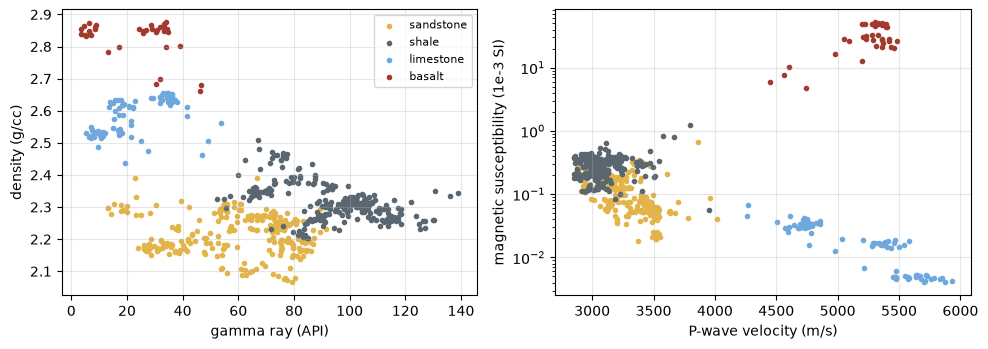

In [2]:
abc, d = load()
print("A–C공:", abc.shape, "· D공:", d.shape)
print(abc.groupby(["시추공", "암상"]).size().unstack(fill_value=0))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for l in LITHS:
    s = abc[abc["암상"] == l]
    ax[0].scatter(s["감마선_API"], s["밀도_gcc"], s=9, color=COLORS[l], label=LITH_EN[l])
    ax[1].scatter(s["P파속도_mps"], s["대자율_mSI"], s=9, color=COLORS[l], label=LITH_EN[l])
ax[0].set_xlabel("gamma ray (API)"); ax[0].set_ylabel("density (g/cc)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("P-wave velocity (m/s)"); ax[1].set_ylabel("magnetic susceptibility (1e-3 SI)"); ax[1].set_yscale("log")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()


## 2. Part A — k-NN 분류 · AI에게 묻기 (5분)

아래 프롬프트를 **그대로** 보내고 CSV 두 개를 첨부하세요(첨부가 안 되면 처음 몇십 행을 붙여 넣기). 후속 질문은 자유지만, **처음 답은 꼭 기록**합니다.

> 첨부한 시추 코어 물성 자료(core_wells_ABC.csv)로 암상(사암 · 셰일 · 석회암 · 현무암)을 분류하는 k-NN 모델을 파이썬(scikit-learn)으로 만들고 정확도를 구해 줘. 그다음 새 시추공 자료(core_well_D.csv)의 암상을 예측해 줘.

**AI의 답 기록** (아래를 채우세요)
- 입력(특성)으로 쓴 열: 밀도_gcc, P파속도_mps, 공극률_pct, 감마선_API, 대자율_mSI (시추공·깊이는 제외).
- 표준화를 했나? 했다면 무엇에 맞춰(fit) 했나 — 훈련 자료 · 전체 · D공 따로: StandardScaler를 Pipeline 안에서 각 훈련 폴드에만 fit. 최종 예측은 A–C 전체에 fit하고 D공은 transform만 적용.
- 훈련 / 검증을 어떻게 나눴나(비율, 무작위?): 시추공 하나를 통째로 제외하는 LeaveOneGroupOut (400행 훈련/200행 검증, 3회). 비교용 층화 무작위 70/30 분할(random_state=0).
- k는 얼마이고 어떻게 정했나: k=5, 기본값으로 사전 고정 (최적값 탐색은 하지 않음).
- AI가 보고한 정확도: 시추공 단위 검증 88.50% (A 86.0%, B 97.0%, C 82.5%). 비교용 무작위 검증 100.0%, 훈련 99.29%. 새 시추공 성능 판단에는 시추공 단위 검증을 사용.
- D공 예측 결과(암상별 개수): 사암 39, 셰일 117, 석회암 26, 현무암 18. 밀도를 /1000으로 단위 보정한 뒤 예측. D공 정답이 없어 D공 자체 정확도는 알 수 없으며, 업체 간 보정 차이는 추가 확인 필요.


In [3]:
"""A–C 시추공으로 k-NN을 검증하고 D공 암상을 예측한다."""
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 스크립트와 노트북(저장소 루트 또는 실습5)에서 모두 실행 가능.
BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (BASE / "core_wells_ABC.csv").exists():
    BASE = BASE / "실습5"
FEATURES = ["밀도_gcc", "P파속도_mps", "공극률_pct", "감마선_API", "대자율_mSI"]
LABELS = ["사암", "셰일", "석회암", "현무암"]
abc = pd.read_csv(BASE / "core_wells_ABC.csv")
d = pd.read_csv(BASE / "core_well_D.csv")
for name, frame in [("ABC", abc), ("D", d)]:
    if not np.isfinite(frame[FEATURES].to_numpy(dtype=float)).all():
        raise ValueError(f"{name}: 결측값 또는 비유한 물성값을 확인하세요.")
if abc["암상"].isna().any() or set(abc["암상"]) != set(LABELS):
    raise ValueError("학습 자료의 암상 라벨을 확인하세요.")

# 제공된 D 파일의 밀도는 kg/m³로 기록됨. 원자료는 수정하지 않는다.
print("원자료 밀도 범위:", {"ABC": (abc["밀도_gcc"].min(), abc["밀도_gcc"].max()),
                                  "D": (d["밀도_gcc"].min(), d["밀도_gcc"].max())})
d_fix = d.copy()
if not d_fix["밀도_gcc"].between(1900, 3100).all():
    raise ValueError("D 밀도 단위가 예상과 다릅니다. /1000 변환을 재확인하세요.")
d_fix["밀도_gcc"] = d_fix["밀도_gcc"] / 1000

# k=5는 사전에 고정한 기본값이며, 검증 점수로 최적화하지 않았다.
# Pipeline을 사용해 각 훈련 폴드에서만 표준화 계수를 학습한다.
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
X, y, groups = abc[FEATURES], abc["암상"], abc["시추공"]
pred_well = cross_val_predict(model, X, y, cv=LeaveOneGroupOut(), groups=groups)
print(f"시추공 단위 검증 정확도: {accuracy_score(y, pred_well):.4%}")
for well in sorted(groups.unique()):
    mask = groups == well
    print(f"  {well}공: {accuracy_score(y[mask], pred_well[mask]):.4%}")
cm = pd.DataFrame(confusion_matrix(y, pred_well, labels=LABELS),
                  index=pd.Index(LABELS, name="실제"), columns=LABELS)
print("혼동행렬 (행=실제, 열=예측):\n", cm)

# 비교용: 같은 층의 이웃 시료가 양쪽에 섞여 점수가 낙관적일 수 있다.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
model.fit(Xtr, ytr)
print(f"무작위 70/30 훈련 정확도: {model.score(Xtr, ytr):.4%}")
print(f"무작위 70/30 검증 정확도 (비교용): {model.score(Xte, yte):.4%}")

# 최종 모델은 A–C 전체로 학습. D공에는 transform과 predict만 적용한다.
model.fit(X, y)
pred_D = model.predict(d_fix[FEATURES])
result = d_fix.assign(예측_암상=pred_D)
output = BASE / "core_well_D_knn_predictions.csv"
result.to_csv(output, index=False, encoding="utf-8-sig")
print("D공 예측 개수:\n", result["예측_암상"].value_counts().reindex(LABELS, fill_value=0))
print("저장:", output)
print("D공에는 정답 라벨이 없어 실제 예측 정확도를 계산할 수 없습니다.")


원자료 밀도 범위: {'ABC': (np.float64(2.065), np.float64(2.875)), 'D': (np.int64(2201), np.int64(2836))}
시추공 단위 검증 정확도: 88.5000%
  A공: 86.0000%
  B공: 97.0000%
  C공: 82.5000%
혼동행렬 (행=실제, 열=예측):
       사암   셰일  석회암  현무암
실제                     
사암   233    4    1    0
셰일    61  181    0    0
석회암    1    0   83    0
현무암    0    0    2   34
무작위 70/30 훈련 정확도: 99.2857%
무작위 70/30 검증 정확도 (비교용): 100.0000%
D공 예측 개수:
 예측_암상
사암      39
셰일     117
석회암     26
현무암     18
Name: count, dtype: int64
저장: /workspaces/basic-geological-data-science/실습5/core_well_D_knn_predictions.csv
D공에는 정답 라벨이 없어 실제 예측 정확도를 계산할 수 없습니다.


## 3. 검증 — AI의 분류를 확인한다 (25분)

### 3-1 ★ D공 자료부터 — 단위가 같은가
명세서 ③: D공은 다른 업체 자료. 두 파일의 값을 정상 범위와 나란히 봅니다.

In [4]:
check_ranges(abc, "A–C공")
check_ranges(d, "D공")


A–C공


,열,최솟값,중앙값,최댓값,정상 범위,범위 밖 행
0,밀도_gcc,2.06500,2.293,2.875,1.9–3.1,0
1,P파속도_mps,2851.00000,3220.000,5930.000,1500–7000,0
2,공극률_pct,2.90000,23.500,36.000,0–45,0
3,감마선_API,3.30000,71.400,139.100,0–250,0
4,대자율_mSI,0.00402,0.173,51.700,0–100,0


D공


,열,최솟값,중앙값,최댓값,정상 범위,범위 밖 행
0,밀도_gcc,2201.00000,2312.0000,2836.0,1.9–3.1,200
1,P파속도_mps,2876.00000,3304.0000,5172.0,1500–7000,0
2,공극률_pct,6.60000,23.1500,27.2,0–45,0
3,감마선_API,30.00000,92.2500,133.7,0–250,0
4,대자율_mSI,0.00955,0.1955,46.3,0–100,0


D공의 어느 열이 범위를 벗어났나? A–C공과 **몇 배** 차이인가? 아래 칸에 **한 줄**을 써서 고친 표 `d_fix`를 만드세요. AI의 D공 예측이 이상했다면 이것 때문인지 확인합니다.

In [5]:
d_fix = d.copy()
d_fix["밀도_gcc"] = d_fix["밀도_gcc"] / 1000  # kg/m³ → g/cm³

check_ranges(d_fix, "D공(고친 뒤)")


D공(고친 뒤)


,열,최솟값,중앙값,최댓값,정상 범위,범위 밖 행
0,밀도_gcc,2.20100,2.3120,2.836,1.9–3.1,0
1,P파속도_mps,2876.00000,3304.0000,5172.000,1500–7000,0
2,공극률_pct,6.60000,23.1500,27.200,0–45,0
3,감마선_API,30.00000,92.2500,133.700,0–250,0
4,대자율_mSI,0.00955,0.1955,46.300,0–100,0


### 3-2 ★ 표준화 — 거리는 단위를 탄다
k-NN은 **거리**로 이웃을 고릅니다. 열마다 퍼짐(표준편차)이 수천 배 다르면 어느 열이 거리를 좌우할까요?

In [6]:
print("열마다 표준편차:", abc[FEATURES].std().round(3).to_dict())
knn_report(abc, k=5, scale=False, split="random")
knn_report(abc, k=5, scale=True, split="random")


열마다 표준편차: {'밀도_gcc': 0.18, 'P파속도_mps': 843.866, '공극률_pct': 8.183, '감마선_API': 31.77, '대자율_mSI': 8.086}
[무작위 70/30 · k=5 · 표준화 X]  훈련 정확도 0.893 · 검증 정확도 0.883
[무작위 70/30 · k=5 · 표준화 O]  훈련 정확도 0.993 · 검증 정확도 1.000


### 3-3 ★ 나누는 법 — 같은 층의 이웃이 시험지에 들어가면
무작위 70/30으로 나누면 같은 층의 0.5 m 이웃이 훈련과 검증에 갈라져 들어갑니다 — 시험 문제를 미리 본 셈입니다. 우리가 실제로 하려는 일은 **처음 보는 시추공(D공)**의 예측이므로, **시추공 하나를 통째로 빼고** 나머지 둘로 배워 뺀 공을 맞히는 검증이 그 상황과 같습니다(9주차 다섯 질문의 3번 '나누는 법', 11/16의 자기상관).

In [7]:
knn_report(abc, k=5, scale=True, split="random")
pred_well = knn_report(abc, k=5, scale=True, split="well")


[무작위 70/30 · k=5 · 표준화 O]  훈련 정확도 0.993 · 검증 정확도 1.000
[시추공 단위 · k=5 · 표준화 O]  전체 0.885  (A공 0.860 · B공 0.970 · C공 0.825)


### 3-4 ☆ k 고르기 — 무엇으로 고르나
k마다 검증 정확도를 두 방식으로 봅니다. k를 바꿔서 생기는 차이와, 나누는 법을 바꿔서 생기는 차이 중 어느 쪽이 큰가요?

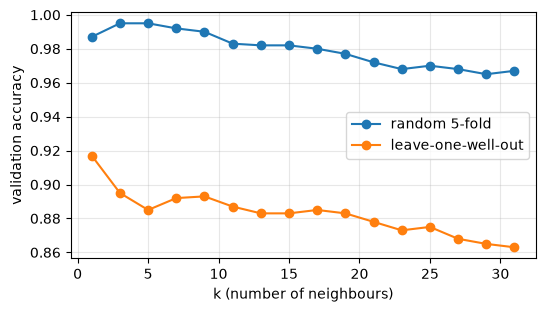

,무작위 5겹,시추공 단위
k,,
1,0.987,0.917
3,0.995,0.895
5,0.995,0.885
7,0.992,0.892
9,0.990,0.893
11,0.983,0.887
13,0.982,0.883
15,0.982,0.883
17,0.980,0.885


In [8]:
k_curve(abc)


### 3-5 ★ 정확도만 보지 말 것 — 혼동행렬과 기준선
정확도 하나로는 **무엇을 무엇으로 틀렸는지** 모릅니다. 시추공 단위 검증(3-3)의 예측으로 혼동행렬을 봅니다.

In [9]:
confusion(abc, pred_well)


,예측 사암,예측 셰일,예측 석회암,예측 현무암
실제 사암,233,4,1,0
실제 셰일,61,181,0,0
실제 석회암,1,0,83,0
실제 현무암,0,0,2,34


암상별 재현율(실제 그 암상 중 맞힌 비율): {'사암': 0.979, '셰일': 0.748, '석회암': 0.988, '현무암': 0.944}
정확도 0.885 · 기준선(늘 '셰일'이라고 답하면) 0.403


### 3-6 ★ D공 예측 — 깊이 기둥으로 보기
A–C공 전체로 배워 **고친 D공**(`d_fix`)의 암상을 예측합니다. 대자율이 큰 구간이 현무암으로, 감마선이 높은 구간이 셰일로 나왔나요? 물성과 예측이 모순되는 곳을 찾아보세요.

암상 기둥, 대자율 로그, **대자율 ≥ 7 mSI 구간**, 감마선 로그, **감마선 ≥ 65 API 구간**을 같은 깊이 축으로 비교합니다. 색이 있는 구간은 기준 이상, 회색은 기준 미만입니다. 기준은 명세서의 현무암·셰일 참고 범위 하한으로, 암상 확정 기준은 아닙니다. 특히 사암과 셰일의 감마선 범위는 겹칩니다.

**현재 교차검증:** `StandardScaler → KNeighborsClassifier(k=5)` 파이프라인에 `LeaveOneGroupOut`을 적용하고 `시추공`을 그룹으로 지정합니다. A·B·C공을 각각 한 번씩 검증용으로 제외하여 매회 400행으로 훈련하고 200행으로 검증합니다. 표준화도 매회 훈련 자료에서만 학습합니다. 각 행의 미학습 예측을 합친 정확도는 **88.5%**입니다(A 86.0%, B 97.0%, C 82.5%). 무작위 층화 70/30 분할의 100%는 비교용입니다. 현재 k=5는 사전 고정값이며, 3-4의 k별 점수 비교는 탐색용으로 별도의 중첩 교차검증은 아닙니다. 최종 D공 예측에는 A–C공 전체로 다시 학습합니다.


D공 예측 암상 개수: {'셰일': 117, '사암': 39, '석회암': 26, '현무암': 18}


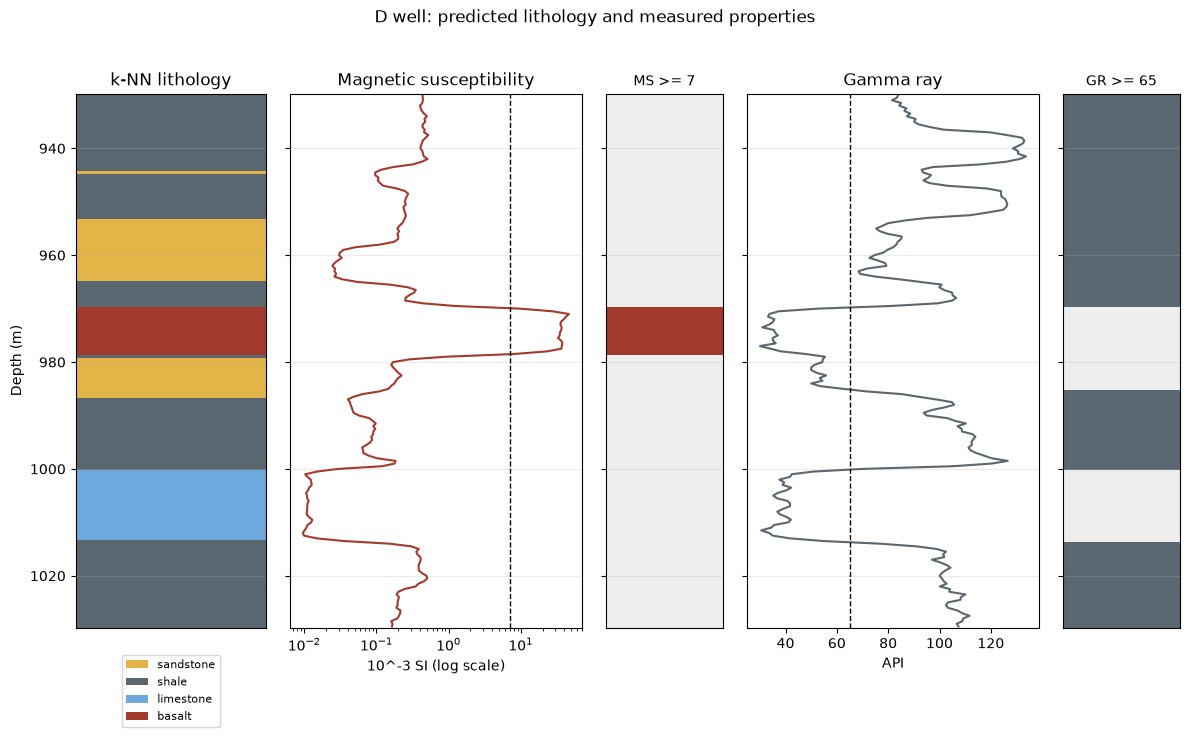

대자율 >= 7 mSI: 18개 중 현무암 예측 18개, 다른 암상 0개
감마선 >= 65 API: 142개 중 셰일 예측 115개, 다른 암상 27개


In [10]:
# D공의 밀도 단위를 보정한 자료로 예측한다.
pred_D = predict_D(abc, d_fix, k=5)

# 명세서의 참고 범위: 현무암 대자율 7–50, 셰일 감마선 65–120.
# 아래 기준은 비교를 위한 표시 기준이며, 암상을 확정하는 분류 규칙은 아니다.
MS_HIGH, GAMMA_HIGH = 7.0, 65.0
plot_d = d_fix.assign(예측_암상=pred_D).sort_values("깊이_m")
z = plot_d["깊이_m"].to_numpy()
ms = plot_d["대자율_mSI"].to_numpy()
gamma = plot_d["감마선_API"].to_numpy()
# 각 관측값을 인접 깊이의 중간점까지 표시한다.
edges = np.r_[z[0] - (z[1]-z[0])/2, (z[:-1]+z[1:])/2,
              z[-1] + (z[-1]-z[-2])/2]
heights = np.diff(edges)
centers = (edges[:-1] + edges[1:]) / 2

fig, axes = plt.subplots(1, 5, figsize=(12, 8), sharey=True,
                         gridspec_kw={"width_ratios": [1.3, 2, 0.8, 2, 0.8]})
for lith in LITHS:
    mask = plot_d["예측_암상"].to_numpy() == lith
    axes[0].barh(centers[mask], np.ones(mask.sum()), height=heights[mask], left=-0.5,
                 color=COLORS[lith], label=LITH_EN[lith])
axes[0].set_title("k-NN lithology")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), fontsize=8)

axes[1].plot(ms, z, color=COLORS["현무암"])
axes[1].set_xscale("log")
axes[1].axvline(MS_HIGH, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Magnetic susceptibility")
axes[1].set_xlabel("10^-3 SI (log scale)")
axes[3].plot(gamma, z, color=COLORS["셰일"])
axes[3].axvline(GAMMA_HIGH, color="black", linestyle="--", linewidth=1)
axes[3].set_title("Gamma ray")
axes[3].set_xlabel("API")

for ax, mask, color, title in [
    (axes[2], ms >= MS_HIGH, COLORS["현무암"], "MS >= 7"),
    (axes[4], gamma >= GAMMA_HIGH, COLORS["셰일"], "GR >= 65"),
]:
    ax.set_facecolor("#eeeeee")
    ax.barh(centers[mask], np.ones(mask.sum()), height=heights[mask], left=-0.5, color=color)
    ax.set_title(title, fontsize=10)
for ax in [axes[0], axes[2], axes[4]]:
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([])
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylim(edges[-1], edges[0])  # 깊이는 아래쪽으로 증가
axes[0].set_ylabel("Depth (m)")
fig.suptitle("D well: predicted lithology and measured properties")
fig.tight_layout(rect=(0, 0.06, 1, 0.96))
plt.show()

# 강조된 구간과 예측이 얼마나 일치하는지 수치로도 확인한다.
for title, mask, lith in [("대자율 >= 7 mSI", ms >= MS_HIGH, "현무암"),
                          ("감마선 >= 65 API", gamma >= GAMMA_HIGH, "셰일")]:
    count = int(mask.sum())
    matched = int((plot_d.loc[mask, "예측_암상"] == lith).sum())
    print(f"{title}: {count}개 중 {lith} 예측 {matched}개, 다른 암상 {count-matched}개")


### 해석 (Part A)

**Q1. AI의 D공 예측은 어떻게 나왔고, 무엇을 보고 이상하다는 것을 알았나? 원인과 고친 방법은?**

최초 AI 답에서는 밀도 단위를 먼저 보정해 D공을 예측했다. 비교를 위해 같은 모델(표준화 + k=5)에 보정 전 D공을 넣으면 **200개 모두 현무암**으로 예측된다. 그러나 대자율이 낮은 구간과 감마선이 높은 구간까지 모두 현무암으로 분류되어 물성과 모순된다. A–C공의 밀도는 2.065–2.875 g/cm³인데 D공은 같은 열 이름 아래 2201–2836으로 기록되어 있었다. D공 밀도가 kg/m³ 단위로 들어가 약 1,000배 차이가 난 것이 원인이다. 훈련 자료에 맞춘 표준화만으로는 이러한 단위 불일치가 해결되지 않는다.

원자료를 복사한 `d_fix`에서 `d_fix["밀도_gcc"] = d_fix["밀도_gcc"] / 1000`으로 g/cm³ 단위에 맞췄다. 보정 후 예측은 **사암 39개, 셰일 117개, 석회암 26개, 현무암 18개**였다. 3-6의 깊이 기둥에서 대자율이 7 mSI 이상인 18개는 모두 현무암으로 예측되었고, 감마선이 65 API 이상인 142개 중 115개는 셰일로 예측되었다. 다만 이 기준값들은 물성과 예측을 비교하는 참고값이며, 정답 판정 기준은 아니다. 특히 사암과 셰일은 감마선 범위가 겹친다.

**Q2. D공에 대해 기대할 정확도로 무작위 분할과 시추공 단위 중 어느 숫자를 보고하겠나? 숫자와 이유는?**

새 시추공에 대한 성능의 참고값으로 **시추공 단위 교차검증 정확도 88.5%**를 보고한다. `LeaveOneGroupOut`으로 A·B·C공을 각각 한 번씩 통째로 제외하고, 나머지 두 공의 400행으로 학습해 제외한 공의 200행을 예측했다. 검증 정확도는 A공 86.0%, B공 97.0%, C공 82.5%이며, 전체 미학습 예측 600개 중 531개를 맞혔다. `StandardScaler`는 파이프라인 안에서 각 훈련 폴드에만 맞췄으며, k=5는 사전에 고정했다.

비교용 무작위 층화 70/30 분할에서는 검증 정확도가 100%였다. 그러나 이 자료는 0.5 m 간격이고 검층의 수직 분해능은 약 1.5 m라, 같은 층의 가까운 시료가 매우 비슷하다. 무작위 분할이나 랜덤 5-fold에서는 이런 이웃 시료가 훈련과 검증에 나뉘어 점수가 낙관적으로 나올 수 있다. 처음 보는 D공을 예측하려는 목적에는 공 하나를 통째로 제외하는 방식이 더 적절하다. 단, **88.5%는 D공에서 직접 측정한 정확도가 아니다.** D공에는 정답 라벨이 없고 업체 간 측정·보정 차이도 있을 수 있어 실제 성능은 확인할 수 없다.

**Q3. 가장 많이 헷갈린 두 암상은? 어떤 물성이 겹쳐서인가?**

시추공 단위 검증의 혼동행렬에서 가장 많이 혼동한 두 암상은 **사암과 셰일**이다. 실제 셰일을 사암으로 예측한 경우가 61개, 실제 사암을 셰일로 예측한 경우가 4개로, 두 암상 사이의 혼동이 전체 오류 69개 중 65개였다. 특히 셰일을 사암으로 분류하는 오류가 많았다.

명세서의 흔한 값 범위에서 두 암상은 밀도 **2.2–2.3 g/cm³**, P파 속도 **2,900–3,400 m/s**, 공극률 **20–28%**, 감마선 **65–85 API**, 대자율 **0.1–0.3 mSI** 구간이 겹친다. 따라서 다섯 물성으로 계산한 거리에서도 서로 가까운 시료가 생길 수 있다. 층 경계에서 위아래 층의 측정값이 섞이는 현상도 혼동에 영향을 줄 수 있지만, 개별 오류의 원인을 확정하려면 해당 깊이의 물성을 추가로 확인해야 한다.


## 4. Part B — k-means 군집 · 라벨 없이 묶으면 (20분)

D공에는 코어가 없습니다. 라벨 없이 **물성이 비슷한 시료끼리** 묶으면 어떤 무리가 나올까요?

> 새 시추공 자료(core_well_D.csv)를 k-means로 군집 분석하는 파이썬 코드를 짜 줘. 군집 수는 엘보 방법으로 정하고, 각 군집이 어떤 암석인지 해석해 줘. (밀도 열이 kg/m³로 잘못 들어가 있어서 g/cm³로 고친 표를 쓸 거야.)

**AI의 답 기록**
- 표준화를 했나: 밀도를 보정한 D공의 물성 5개에 StandardScaler 적용. D공 내부 군집 탐색이므로 D공 전체에 fit.
- 엘보로 고른 k: **3**. k=1~8의 inertia는 1000.0, 282.8, 121.0, 66.7, 51.5, 40.2, 33.1, 28.4로 k=3 부근에서 감소가 완만해진다. 실루엣도 k=3에서 0.757로 가장 높아 선택을 보조한다. 엘보는 유일한 정답을 주지 않으므로 k=4도 비교한다.
- 각 군집의 해석(무엇을 근거로): 원래 단위의 물성 중앙값을 명세서와 비교했다. 아래 번호는 이번 코드 실행 기준이다.

| 군집(k=3) | 시료 수 | 밀도(g/cm³) | P파(m/s) | 공극률(%) | 감마선(API) | 대자율(mSI) | 해석 |
|---|---:|---:|---:|---:|---:|---:|---|
| 0 | 153 | 2.299 | 3143.0 | 23.6 | 100.9 | 0.2000 | 사암·셰일 혼합 추정 |
| 1 | 31 | 2.560 | 4962.0 | 8.9 | 40.4 | 0.0113 | 석회암 추정 |
| 2 | 16 | 2.805 | 5059.5 | 7.3 | 35.1 | 36.2500 | 현무암 추정 |

군집 0은 낮은 밀도·속도와 높은 공극률을 보이는 쇄설암 무리다. 감마선 중앙값은 셰일 쪽이지만, k=4에서 감마선 중앙값 81.75 API의 사암 쪽(62개)과 108.2 API의 셰일 쪽(91개)으로 갈라지므로 군집 전체를 셰일로 단정하지 않았다. 군집 1은 높은 속도와 낮은 공극률, 매우 낮은 대자율이 석회암과 부합한다. 다만 감마선 중앙값 40.4 API는 명세서의 흔한 범위 상한 40을 조금 넘어, 업체 간 보정 차이 가능성 등을 확인할 필요가 있다. 군집 2는 높은 밀도와 매우 큰 대자율이 현무암과 부합한다.

**해석의 한계:** 군집 수와 실제 암상 수는 같을 필요가 없다. k=3은 사암·셰일을 충분히 분리하지 못하며, k=4의 세분화도 정답을 보장하지 않는다. 군집 번호에는 암석학적 의미가 없고, D공에는 정답 라벨이 없어 실루엣 점수를 분류 정확도로 해석할 수 없다.


,k,inertia,silhouette,inertia 감소량
0,1,1000.000,NaN,NaN
1,2,282.753,0.728,717.247
2,3,120.981,0.757,161.772
3,4,66.707,0.535,54.273
4,5,51.526,0.501,15.182
5,6,40.202,0.525,11.324
6,7,33.069,0.525,7.132
7,8,28.382,0.524,4.687


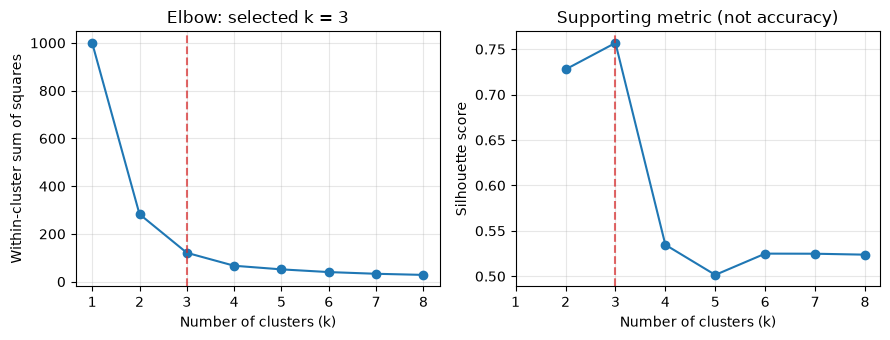

선택한 k=3: 원래 단위의 중앙값


,시료 수,밀도_gcc,P파속도_mps,공극률_pct,감마선_API,대자율_mSI,해석
군집,,,,,,,
0,153,2.299,3143.0,23.6,100.9,0.2000,사암·셰일 혼합 추정
1,31,2.560,4962.0,8.9,40.4,0.0113,석회암 추정
2,16,2.805,5059.5,7.3,35.1,36.2500,현무암 추정


비교용 k=4: 원래 단위의 중앙값


,시료 수,밀도_gcc,P파속도_mps,공극률_pct,감마선_API,대자율_mSI,해석
군집,,,,,,,
0,62,2.2555,3371.0,24.65,81.75,0.1595,사암 쪽 추정
1,31,2.5600,4962.0,8.90,40.40,0.0113,석회암 추정
2,91,2.3150,3057.0,22.90,108.20,0.2490,셰일 쪽 추정
3,16,2.8050,5059.5,7.30,35.10,36.2500,현무암 추정


저장: /workspaces/basic-geological-data-science/실습5/core_well_D_kmeans_clusters.csv
암석 이름은 물성에 근거한 추정이며, 정답 라벨이 없어 분류 정확도는 계산하지 않습니다.


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 앞에서 g/cm³로 보정한 표를 사용한다. 다시 /1000 하지 않는다.
df = d_fix.copy()
features_km = ["밀도_gcc", "P파속도_mps", "공극률_pct", "감마선_API", "대자율_mSI"]
assert df["밀도_gcc"].between(1.9, 3.1).all(), "밀도 단위 보정을 확인하세요."
assert np.isfinite(df[features_km].to_numpy(dtype=float)).all(), "결측값을 확인하세요."

# D공 내부의 군집 탐색이므로 D공 전체에 표준화를 fit한다.
# k-NN의 새 시추공 예측·교차검증과는 목적이 다르다.
scaler_km = StandardScaler()
Z_km = scaler_km.fit_transform(df[features_km])
ks = list(range(1, 9))
models_km = {k: KMeans(n_clusters=k, n_init=20, random_state=0).fit(Z_km) for k in ks}
scan_km = pd.DataFrame({
    "k": ks,
    "inertia": [models_km[k].inertia_ for k in ks],
    "silhouette": [silhouette_score(Z_km, models_km[k].labels_) if k > 1 else np.nan for k in ks],
})
scan_km["inertia 감소량"] = -scan_km["inertia"].diff()
display(scan_km.round(3))

# 엘보 곡선을 보고 k=3 선택: 2→3의 감소량 161.8, 3→4는 54.3.
# 시각적 판단에는 주관성이 있어 k=4도 비교한다. 실루엣은 보조 지표이다.
best_k = 3
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(ks, scan_km["inertia"], "o-")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[0].set_title("Elbow: selected k = 3")
axes[1].plot(ks[1:], scan_km["silhouette"].iloc[1:], "o-")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Supporting metric (not accuracy)")
for ax in axes:
    ax.axvline(best_k, color="C3", linestyle="--", alpha=0.7)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(ks)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# 해석에는 표준화 공간의 중심 대신 원래 단위의 군집별 중앙값을 사용한다.
def cluster_summary(k):
    labels = models_km[k].labels_
    grouped = df[features_km].assign(군집=labels).groupby("군집")
    summary = grouped.median()
    summary.insert(0, "시료 수", grouped.size())
    return summary

summary_k3 = cluster_summary(3)
summary_k4 = cluster_summary(4)
# 아래 군집 번호는 이 자료·특성·random_state=0·n_init=20 실행 결과에 대응한다.
# 군집 번호 자체는 암석 이름이나 순서를 뜻하지 않는다.
interpret_k3 = {0: "사암·셰일 혼합 추정", 1: "석회암 추정", 2: "현무암 추정"}
interpret_k4 = {0: "사암 쪽 추정", 1: "석회암 추정", 2: "셰일 쪽 추정", 3: "현무암 추정"}
summary_k3["해석"] = summary_k3.index.map(interpret_k3)
summary_k4["해석"] = summary_k4.index.map(interpret_k4)
print("선택한 k=3: 원래 단위의 중앙값")
display(summary_k3.round(4))
print("비교용 k=4: 원래 단위의 중앙값")
display(summary_k4.round(4))

result_km = df.assign(군집_k3=models_km[3].labels_)
result_km["군집_해석"] = result_km["군집_k3"].map(interpret_k3)
output_dir = Path.cwd() if Path("core_well_D.csv").exists() else Path("실습5")
output_km = output_dir / "core_well_D_kmeans_clusters.csv"
result_km.to_csv(output_km, index=False, encoding="utf-8-sig")
print("저장:", output_km)
print("암석 이름은 물성에 근거한 추정이며, 정답 라벨이 없어 분류 정확도는 계산하지 않습니다.")


### 4-1 ★ k 고르기 — 엘보와 실루엣
군집 내 제곱합(엘보)은 k가 커질수록 늘 줄어듭니다. 실루엣은 '내 군집과 얼마나 가깝고 옆 군집과 얼마나 먼가'(−1 ~ 1, 클수록 잘 갈림). 두 기준이 같은 k를 가리키나요?

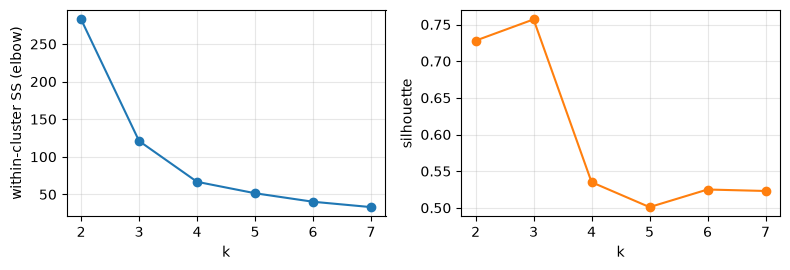

,군집 내 제곱합,실루엣
k,,
2,282.753,0.728
3,120.981,0.757
4,66.707,0.535
5,51.526,0.501
6,40.202,0.525
7,33.072,0.523


In [19]:
scan = kmeans_scan(d_fix[FEATURES], scale=True)
scan


### 4-2 ★ 군집을 암석으로 읽기 — 중심값을 명세서 표와 대조
군집 번호(0, 1, 2 …)에는 뜻이 없습니다. 군집마다 **원래 단위의 중앙값**을 데이터 명세서의 '암상별로 흔한 값' 표와 비교해 이름을 붙이세요. k = 3과 k = 4는 무엇이 다른가요?

In [20]:
print("k = 3"); lab3 = kmeans_centers(d_fix, k=3)
print("k = 4"); lab4 = kmeans_centers(d_fix, k=4)


k = 3


,시료 수,밀도_gcc,P파속도_mps,공극률_pct,감마선_API,대자율_mSI
군집,,,,,,
0,153,2.30,3143.0,23.6,100.9,0.20
1,31,2.56,4962.0,8.9,40.4,0.01
2,16,2.80,5059.5,7.3,35.1,36.25


k = 4


,시료 수,밀도_gcc,P파속도_mps,공극률_pct,감마선_API,대자율_mSI
군집,,,,,,
0,62,2.26,3371.0,24.65,81.75,0.16
1,31,2.56,4962.0,8.90,40.40,0.01
2,91,2.32,3057.0,22.90,108.20,0.25
3,16,2.80,5059.5,7.30,35.10,36.25


### 4-3 ★ 두 방법 맞대기 — k-NN(라벨로 배움) vs k-means(라벨 없이 묶음)
서로 다른 방법이 같은 답을 내면 믿을 만하고, 엇갈리는 곳은 다시 볼 곳입니다.

k-NN 예측,사암,석회암,셰일,현무암
k-means 군집(k=4),,,,
0,39,0,23,0
1,0,26,3,2
2,0,0,91,0
3,0,0,0,16


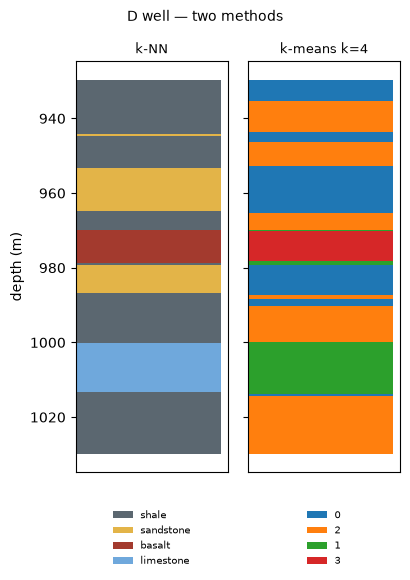

In [21]:
display(pd.crosstab(pd.Series(lab4, name="k-means 군집(k=4)"), pd.Series(pred_D, name="k-NN 예측")))
depth_strip(d_fix["깊이_m"], {"k-NN": pred_D, "k-means k=4": lab4}, "D well — two methods")


### 4-4 ☆ 표준화하지 않으면 · 대자율을 로그로 보면
대자율은 암석마다 수십~수천 배 차이 납니다(명세서 표). 이런 열은 흔히 로그로 바꿔 씁니다.

표준화 X


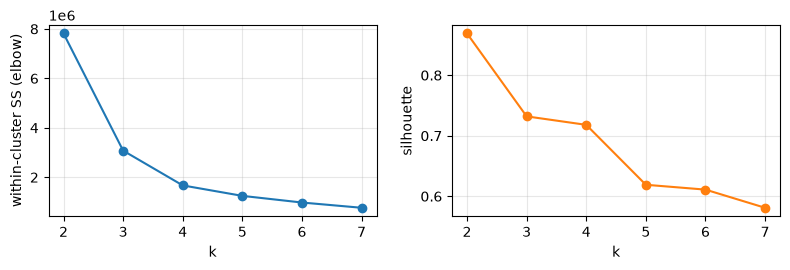

표준화 O + 대자율 log10


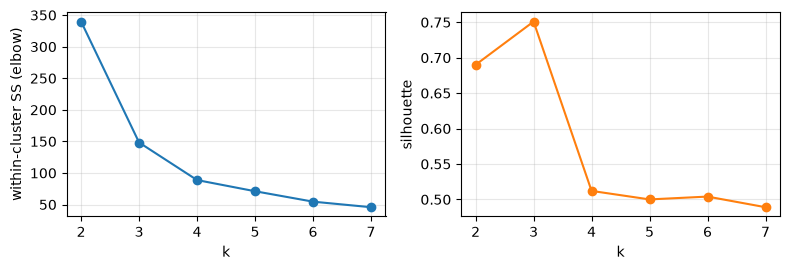

,군집 내 제곱합,실루엣
k,,
2,339.791,0.690
3,148.236,0.751
4,88.764,0.512
5,71.066,0.500
6,54.571,0.504
7,45.767,0.489


In [22]:
print("표준화 X"); kmeans_scan(d_fix[FEATURES], scale=False)
print("표준화 O + 대자율 log10"); kmeans_scan(d_fix[FEATURES], scale=True, log_ms=True)


### 4-5 ☆ 엇갈린 시료의 감마선 — D공 검층기는 A–C공과 같게 읽을까?
k-NN은 '셰일', k-means는 '사암 쪽 무리'라고 한 시료들을 모아 봅니다. 감마선이 거의 없는 석회암 · 현무암에서도 두 자료를 비교해 보세요.

In [23]:
cen = d_fix[FEATURES].assign(c=lab4).groupby("c").median()
clastic = cen[cen["P파속도_mps"] < 4000]
sand_c = clastic["감마선_API"].idxmin()                       # 쇄설암 중 감마선이 낮은 쪽 = 사암 쪽 무리
dis = (pd.Series(pred_D) == "셰일").values & (lab4 == sand_c)
print(f"엇갈린 시료 {dis.sum()}개 · 감마선 {d_fix.loc[dis, '감마선_API'].min():.0f}–{d_fix.loc[dis, '감마선_API'].max():.0f} API")
print("A–C공, 실제 암상별 감마선 중앙값:", abc.groupby("암상")["감마선_API"].median().round(1).to_dict())
print("D공, k-NN 예측별 감마선 중앙값:  ", d_fix.groupby(pred_D)["감마선_API"].median().round(1).to_dict())


엇갈린 시료 23개 · 감마선 77–102 API
A–C공, 실제 암상별 감마선 중앙값: {'사암': 62.4, '석회암': 19.0, '셰일': 93.8, '현무암': 27.8}
D공, k-NN 예측별 감마선 중앙값:   {'사암': 75.3, '석회암': 39.2, '셰일': 104.3, '현무암': 35.3}


### 해석 (Part B)

**Q4. 고른 k와 이유, 각 군집의 이름과 근거(중앙값)는?**

최종 군집 수는 **k=3**으로 선택했다. 표준화한 물성 5개로 계산한 군집 내 제곱합은 k=1~5에서 각각 1000.0, 282.8, 121.0, 66.7, 51.5였다. k=3 부근부터 감소 폭이 작아지는 엘보를 주된 근거로 삼았으며, 실루엣 점수도 k=3에서 **0.757**로 가장 높아 선택을 뒷받침했다(k=2: 0.728, k=4: 0.535). 다만 엘보 위치는 주관적일 수 있어, 사암과 셰일의 분리 가능성을 살펴보는 지질학적 비교용으로 k=4도 확인했다. 실제 암상이 네 종류라고 해서 군집 수를 반드시 4로 정할 필요는 없다.

다음은 k=3 군집의 **원래 단위 물성 중앙값**이다. 군집 번호는 이번 실행에서 붙은 식별자이며 암석 이름 자체를 뜻하지 않는다.

| 군집 | 시료 수 | 밀도(g/cm³) | P파 속도(m/s) | 공극률(%) | 감마선(API) | 대자율(mSI) | 해석 |
|---|---:|---:|---:|---:|---:|---:|---|
| 0 | 153 | 2.299 | 3143.0 | 23.6 | 100.9 | 0.2000 | 사암·셰일 혼합 추정 |
| 1 | 31 | 2.560 | 4962.0 | 8.9 | 40.4 | 0.0113 | 석회암 추정 |
| 2 | 16 | 2.805 | 5059.5 | 7.3 | 35.1 | 36.2500 | 현무암 추정 |

군집 0은 낮은 밀도·속도와 높은 공극률을 보이는 쇄설암 무리다. 감마선 중앙값은 셰일 쪽이지만, k=4에서는 사암 쪽 62개(감마선 중앙값 81.75 API)와 셰일 쪽 91개(108.20 API)로 나뉘므로 전체를 셰일로 단정하지 않았다. 군집 1은 높은 속도, 낮은 공극률과 매우 낮은 대자율이 석회암에 부합한다. 군집 2는 높은 밀도와 매우 큰 대자율이 현무암의 특징에 부합한다. 이 이름들은 물성에 따른 해석이며 정답 라벨은 아니다.

**Q5 ☆. k-NN과 k-means가 엇갈린 시료는 몇 개, 어느 깊이인가? 4-5의 결과로 볼 때 어느 쪽이 맞을 것 같은가, 왜?**

4-3에서는 비교용 **k=4**의 군집을 0=사암 쪽, 1=석회암 쪽, 2=셰일 쪽, 3=현무암 쪽으로 해석해 k-NN과 비교했다. 이 대응을 기준으로 **200개 중 172개(86%)가 일치하고 28개가 엇갈렸다.** 이 수치는 두 방법의 일치율이지 정확도가 아니다.

이 중 4-5에서 따로 살펴본 **‘k-means는 사암 쪽, k-NN은 셰일’인 시료는 23개**다. 해당 관측 깊이는 다음과 같다(구간 내 간격 0.5 m).

| 관측 깊이(m) | 시료 수 |
|---|---:|
| 930.0–935.0 | 11 |
| 944.0 | 1 |
| 945.0–946.0 | 3 |
| 953.0 | 1 |
| 965.0 | 1 |
| 987.0 | 1 |
| 988.5–990.0 | 4 |
| 1014.0 | 1 |

나머지 **5개**는 k-means가 석회암 쪽으로 묶었지만 k-NN이 현무암으로 예측한 970.0, 978.5 m와 셰일로 예측한 979.0, 1000.0, 1013.5 m다. 이들은 예측 암상이 바뀌는 경계 부근이므로 검층의 수직 분해능에 따른 물성 혼합이 영향을 주었을 가능성이 있다.

4-5의 23개 시료는 감마선이 약 **77–102 API**로 높아 k-NN에서 셰일로 분류되었을 가능성이 있다. 그러나 감마선이 원래 낮은 암상에서도 D공의 값이 A–C공보다 높게 나타난다.

| 암상 | A–C공 실제 암상별 감마선 중앙값(API) | D공 k-NN 예측별 감마선 중앙값(API) |
|---|---:|---:|
| 사암 | 62.4 | 75.3 |
| 셰일 | 93.8 | 104.3 |
| 석회암 | 19.0 | 39.2 |
| 현무암 | 27.8 | 35.3 |

이 차이는 **D공의 감마선 측정·보정 차이 가능성**을 시사한다. 만약 D공 감마선이 전반적으로 높게 측정되었다면, A–C공으로 학습한 k-NN은 일부 사암을 셰일로 예측할 수 있다. 따라서 엇갈린 23개에 대해서는 D공 내부의 상대적인 물성 차이로 묶은 **k-means의 사암 쪽 해석을 검토할 이유가 있다.** 특히 모든 시료에 동일한 감마선 가산 오차가 있다면 D공 자체에 맞춘 표준화에서 그 이동은 제거된다.

다만 위 표는 A–C공의 실제 라벨과 D공의 예측 라벨을 비교한 것이므로, 이 차이만으로 기기 오차를 확정하거나 일정 값을 빼서 보정할 수는 없다. 실제 지질 차이와 예측 오류도 원인일 수 있고, D공의 사암·셰일 물성도 겹친다. **정답 코어와 검층기 보정 기록이 없는 현재로서는 어느 방법이 맞는지 확정하지 않고**, 엇갈린 구간을 추가 확인 대상으로 제시한다.


## 5. Part C ★ — 내 포트폴리오 자료에 모델 하나 (남은 시간 + 집에서)

AI 포트폴리오 작성에 과정에서 활용할 수 있는 **모델 2개 이상 비교 + 정량 성능지표 + 선택 근거**입니다. 오늘은 그중 **첫 모델 하나와 기준선**까지 해 둡니다.

| 내 질문의 답이 … | 모델 | 배운 곳 | 검증 | 기준선(이것보다 나아야 의미가 있다) |
|---|---|---|---|---|
| **수치** (CO₂ 농도, 깊이, 규모, 수위 …) | 회귀 — 직선 · 다항 · 지수 | 9주차 | LOOCV · **시간 자료는 앞뒤로 떼어** | 늘 평균으로 답할 때의 RMSE |
| **범주** (암상, 조구조 환경, 쓰나미 원인, VEI …) | k-NN 분류 | 오늘 Part A | 교차검증 · **같은 화산 · 관측소 · 시추공은 한쪽에** | 늘 가장 많은 범주로 답할 때의 정확도 |
| **라벨 없음** — 무리를 찾고 싶다 (진원 분포, 지화학 시료 …) | k-means 군집 | 오늘 Part B | 실루엣 + **지질학적 해석** | 군집이 이미 알려진 구분(지역 · 암석 · 시기)과 맞는가 |

**자료별 한 줄 주의**
- **지진 목록(기상청 · USGS)**: 진원으로 군집하려면 위경도를 km로 바꾸고(투영) 깊이와 단위를 맞춘 뒤 표준화. 단층 · 섭입대처럼 **길쭉한 무리는 k-means가 잘라 버린다**(개념 페이지 그림 3). 깊이 10 km 고정값은 빼고.
- **마우나로아 CO₂ · 기온**: 수치 목표 → 회귀(직선 vs 2차 vs 계절 항) 비교. 검증은 **마지막 몇 년을 떼어** 맞혀 보기(외삽).
- **GEOROC 지화학**: 조구조 환경 분류(k-NN) — 원소 농도는 **로그**, 같은 화산의 시료는 한쪽에(그룹 단위 검증).
- **SEG 검층**: 오늘과 같은 문제 — **시추공 단위 검증**이 필수.
- **GVP · 쓰나미**: 범주(VEI, 원인) 분류나 회귀 — 먼저 **기록 완전성**(옛 기록의 누락)을 확인.

In [26]:
# 1) 내 자료 읽기 — 왼쪽 폴더에 올린 뒤 이름을 바꾸세요
# my = pd.read_csv("내자료.csv")
# 2) 질문 한 줄:
# 3) 목표(답)와 특성(입력) 열
# target = "..."; features = ["...", "..."]
# 4) 기준선
# baseline(my[target])
# 5-a) 범주 목표: 같은 화산 · 관측소 · 시추공을 나타내는 열이 있으면 groups="열 이름"
# pred = quick_knn(my, target, features, k=5, groups=None)
# 5-b) 라벨 없음:
# kmeans_scan(my[features]); lab = kmeans_centers(my, k=3, features=features)
# 5-c) 수치 목표: 9주차 노트북의 회귀 · LOOCV 도구를 가져와 씁니다


### 모델 카드 (중간 2에 그대로 옮겨 씀)

| 칸 | 내 답 |
|---|---|
| 질문 한 줄 | |
| 목표(답) · 특성(입력) | |
| 전처리 (단위 · 결측 · 변환) | |
| 기준선 (숫자) | |
| 모델 1 · 검증 방법 · 지표 (숫자) | |
| 결과 한 줄 (기준선과 비교해 숫자로) | |
| 11/30에 비교할 모델 2와 이유 | |

## 6. AI 활용 기록지 (중간 2에 옮겨 씀)

| 도구 | 프롬프트(요지) | 산출물 | 검증(무엇으로 확인했나) | 수정(무엇을 고쳤나) |
|---|---|---|---|---|
| | | | | |
| | | | | |
